# Macao quarterly non-gaming expenditure

The central question is **RQ4: Did arrivals, nominal non-gaming expenditure and official spending per visit recover together under same-quarter and annual comparisons?** Comparing overnight and same-day visitors also supports the composition part of RQ1. The companion [daily notebook](analysis.ipynb) examines source composition, daily distributions, calendar models and holdout errors.

The data contain **16 Macao-quarter observations**: four quarters in each of 2019, 2023, 2024 and 2025. Expenditure comes from published estimates in the DSEC Visitor Expenditure Survey; arrivals come from daily administrative counts. We aggregate **1,461 daily records into 16 quarters** before joining by year and quarter. Those daily records supply the arrival denominators; they are not 1,461 expenditure observations. The 16 quarters are not individual visitors or questionnaires.

All expenditure is **nominal, at current prices, in Macao patacas (MOP), excluding gaming**. Spending per visit is in MOP; total expenditure is mainly reported in million MOP. Arrivals count visits, including repeat visits by the same person. We do not interpolate 2020-2022, adjust for prices, decompose growth, estimate causal effects or forecast expenditure.

## How to read and run this notebook

Each of the nine code cells has a purpose, method and course explanation, followed by an interpretation of its saved results. Inputs are fixed files in `data/`. The notebook includes three figures. Changes to inputs or methods require a fresh review of the written interpretation.

Course titles, page numbers and Moodle links appear below; the full syllabus is available through the [course page](https://ummoodle.um.edu.mo/course/view.php?id=46674).

The workflow is **read and validate → aggregate daily arrivals → join one to one → calculate recovery indices and shares → check official versus derived spending per visit → compare annual baselines → plot three figures → save traceable findings**.


## Code cell 1 | Paths and consistent plotting settings

### Purpose

Make the same analysis work as a script or notebook and give data, tables and figures stable locations. This cell prepares the environment; it does not calculate recovery statistics.

### Method

- Import `pandas`, `numpy`, `matplotlib` and utilities for paths, JSON, hashes and dates. The `Agg` backend saves plots without an interactive window; `display(Image(...))` embeds the saved PNGs in the notebook.
- `SPENDING_ROOT` is the script directory when run as a script and the current working directory in a notebook. Run from the project folder.
- Read fixed inputs from this package's `data/` directory. No parent folder or online download can silently replace them.
- Fix the four years and three visitor categories: `total`, `overnight` and `same_day`. Reuse each year's colour and marker across figures.
- `spending_save_table` exports CSVs. `spending_save_figure` applies source notes, layout and resolution consistently, then displays the figure in the notebook.

### Course links

- Tutorial02-02, **50 Years of Data Science**, pp. 69-75: sharing code and data, automated workflows and reproducibility.
- Lecture06, **Introduction to Matplotlib**, pp. 8-32: `pyplot`, colours, markers, DPI and saving figures; pp. 33-45: labels, titles and legends; pp. 68-84: layout. [Lecture06 slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451).


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

SPENDING_ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
SPENDING_DATA = SPENDING_ROOT / "data"
SPENDING_RESULTS = SPENDING_ROOT / "results"
SPENDING_FIGURES = SPENDING_ROOT / "figures"
for spending_dir in (SPENDING_DATA, SPENDING_RESULTS, SPENDING_FIGURES):
    spending_dir.mkdir(exist_ok=True)
SPENDING_INPUT_NAME = "macao_quarterly_spending_2019_2023_2025.csv"
# Read the fixed input files included in this share package.

SPENDING_YEARS = [2019, 2023, 2024, 2025]
SPENDING_KINDS = ["total", "overnight", "same_day"]
SPENDING_YEAR_COLORS = {2019: "#595959", 2023: "#0072B2", 2024: "#009E73", 2025: "#D55E00"}
SPENDING_YEAR_MARKERS = {2019: "o", 2023: "s", 2024: "^", 2025: "D"}
plt.rcParams.update({"figure.dpi": 135, "savefig.dpi": 180, "font.size": 10,
                     "axes.titlesize": 12, "axes.spines.top": False,
                     "axes.spines.right": False})

def spending_save_table(frame, filename):
    frame.to_csv(SPENDING_RESULTS / filename, index=False, encoding="utf-8-sig")

def spending_save_figure(fig, filename, footnote):
    fig.text(.015, .015, footnote, fontsize=8, color="#555555", va="bottom")
    fig.tight_layout(rect=(0, .085, 1, .93))
    fig.savefig(SPENDING_FIGURES / filename, bbox_inches="tight")
    plt.close(fig)
    if "get_ipython" in globals():
        from IPython.display import Image, display
        display(Image(filename=str(SPENDING_FIGURES / filename)))

### Results and contribution to the proposal

Execution count 1 produces no printed statistics or separate plot. This is expected: it defines paths, constants and helper functions. It does not establish data quality; the next cell performs those checks.

This step supports reproducibility rather than answering RQ4 directly. Fixed inputs and saved outputs let readers trace each expenditure value and reproduce each chart.


## Code cell 2 | Aggregate daily arrivals and join by quarter

### Purpose

Compare expenditure and arrivals for the **same year, quarter and visitor category**, while keeping their different sources clear. Expenditure is estimated from a quota-sample survey; arrivals are administrative counts. A quarter-level join does not link respondents to individual arrival records or establish statistical independence between the variables.

### Method

1. Read the expenditure and daily visitor-type tables, parsing `date` as a date variable.
2. Require exactly 16 expenditure rows, unique `year/quarter` keys and all four quarters in each selected year. Check `period_basis == "individual_quarter"` and `price_basis == "nominal_current_prices"`; cumulative expenditure is not accepted as a single quarter.
3. Check that the full daily table has unique dates covering every day from 2017-01-01 to 2025-12-31, with nonmissing, nonnegative total, overnight and analysis-version same-day counts.
4. Derive year, quarter and quality flags; select 2019, 2023, 2024 and 2025. `groupby(["year", "quarter"]).agg(...)` sums arrivals and retains day counts, first and last dates, raw missing-day counts and type-additivity flags.
5. Compute `expected_days` from calendar-quarter boundaries. This handles leap years correctly, including 2024Q1. Retain the quarterly residual `overnight + same_day - total`.
6. Use `merge(..., validate="one_to_one", indicator=True)` on year and quarter. Unique keys prevent row multiplication; `_merge` identifies unmatched quarters. Finally check that expenditure period boundaries match the arrival period boundaries.

### Course links

- Lecture04, **Introduction to Exploratory Data Analysis**, pp. 11-18: rectangular data, observations and variables.
- Tutorial04-01, **ThinkStats2 EDA**, pp. 30-35: errors, missing values, conversions and derived columns; pp. 36-42: validation against published data.
- Pandas acquisition, grouping and joins: [course overview](https://ummoodle.um.edu.mo/mod/page/view.php?id=1149845) and [data wrangling](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153067).


In [2]:
spending = pd.read_csv(SPENDING_DATA / SPENDING_INPUT_NAME)
spending_daily = pd.read_csv(
    SPENDING_DATA / "macao_daily_total_overnight_sameday_2017_2025.csv",
    parse_dates=["date"])
assert len(spending) == 16 and not spending.duplicated(["year", "quarter"]).any()
assert set(zip(spending.year, spending.quarter)) == {
    (year, quarter) for year in SPENDING_YEARS for quarter in range(1, 5)}
assert spending.period_basis.eq("individual_quarter").all()
assert spending.price_basis.eq("nominal_current_prices").all()
assert spending_daily.date.is_unique
assert spending_daily.date.sort_values().tolist() == pd.date_range("2017-01-01", "2025-12-31").tolist()
assert spending_daily[["total", "overnight", "same_day_analysis"]].notna().all().all()
assert spending_daily[["total", "overnight", "same_day_analysis"]].ge(0).all().all()
spending_daily["year"] = spending_daily.date.dt.year
spending_daily["quarter"] = spending_daily.date.dt.quarter
spending_daily["raw_same_day_missing"] = spending_daily.same_day_raw.isna()
spending_daily["raw_type_additivity_flag"] = spending_daily.raw_additivity_residual.fillna(0).ne(0)
spending_daily_selected = spending_daily[spending_daily.year.isin(SPENDING_YEARS)].copy()
spending_quarter_arrivals = spending_daily_selected.groupby(["year", "quarter"]).agg(
    total_arrivals=("total", "sum"), overnight_arrivals=("overnight", "sum"),
    same_day_arrivals=("same_day_analysis", "sum"),
    same_day_raw_known_sum=("same_day_raw", "sum"),
    observed_days=("date", "size"), first_date=("date", "min"), last_date=("date", "max"),
    raw_same_day_missing_days=("raw_same_day_missing", "sum"),
    raw_type_additivity_flag_days=("raw_type_additivity_flag", "sum")
).reset_index()
spending_quarter_arrivals["expected_days"] = [
    pd.Period(f"{row.year}Q{row.quarter}", freq="Q").end_time.normalize().dayofyear -
    pd.Period(f"{row.year}Q{row.quarter}", freq="Q").start_time.dayofyear + 1
    for row in spending_quarter_arrivals.itertuples()]
assert spending_quarter_arrivals.observed_days.eq(spending_quarter_arrivals.expected_days).all()
spending_quarter_arrivals["analysis_type_sum_minus_total_arrivals"] = (
    spending_quarter_arrivals.overnight_arrivals + spending_quarter_arrivals.same_day_arrivals -
    spending_quarter_arrivals.total_arrivals)
spending_joined = spending.merge(spending_quarter_arrivals, on=["year", "quarter"],
                                 how="left", validate="one_to_one", indicator=True)
assert spending_joined._merge.eq("both").all()
spending_joined = spending_joined.drop(columns="_merge").sort_values(["year", "quarter"]).reset_index(drop=True)
assert pd.to_datetime(spending_joined.period_start).eq(spending_joined.first_date).all()
assert pd.to_datetime(spending_joined.period_end).eq(spending_joined.last_date).all()

### Results and contribution to the proposal

**All 16 quarters match, and all 1,461 selected daily records fall within complete calendar quarters.** No raw same-day values are missing in the selected years, so the imputed value from an earlier year does not affect this expenditure analysis.

There are **two raw daily type-additivity flags in 2019Q3**. Their differences cancel at quarter level, so `overnight + same_day - total` is zero in all 16 quarters. A zero quarterly residual does not mean every daily record was anomaly-free; both daily flags and quarterly residuals are retained.

The [quarterly arrivals table](results/spending_quarterly_arrivals.csv) records day counts, boundaries and flags. This gives RQ4 matching periods for numerators and denominators and connects RQ1's overnight composition to expenditure composition. **Quarterly expenditure is never copied across days to enlarge the expenditure sample.**


## Code cell 3 | Recovery indices, visitor shares and percentage points

### Purpose

Put arrivals, expenditure and official spending per visit on a common same-quarter 2019 baseline, despite their different units. Then compare the overnight shares of arrivals and expenditure.

### Method

`spending_baseline` selects the four 2019 quarters. `quarter.map(...)` assigns the matching baseline to each row. For total, overnight and same-day visitors, calculate arrival, nominal expenditure and official per-visit indices: nine index columns in all.

\[
I_{y,q}^{X}=100\times\frac{X_{y,q}}{X_{2019,q}}.
\]

An index of 115.9 means 15.9% above the matching 2019 quarter, not 115.9% growth. Matching Q1 with Q1 and Q4 with Q4 avoids directly mixing seasons. This is a stratified descriptive comparison, **not model-based seasonal adjustment**.

Let overnight arrivals be \(N_o\), total arrivals \(N\), overnight expenditure \(S_o\) and reported total expenditure \(S\):

\[
\text{Overnight arrival share}=100\frac{N_o}{N},\qquad
\text{Overnight expenditure share}=100\frac{S_o}{S}.
\]

Same-day shares follow the same rule. `overnight_to_same_day_official_per_capita_ratio` compares the two official spending-per-visit estimates. A share change is the current share minus its matching 2019 share, measured in **percentage points (pp)**, not relative percentage growth.

Denominators remain the reported totals. The two expenditure components sum to 1 million MOP below the total in 2019Q1 and 1 million above it in 2024Q3. These residuals are retained rather than allocated to either category. All 2019 recovery indices must equal 100.

### Course links

- Tutorial05-02, **Exploring Relationships between Two Variables**, pp. 3-10: conditional proportions, differences and ratios; pp. 43-49: stratification, confounding and interpretation. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848).
- Lecture04, **Introduction to Exploratory Data Analysis**, pp. 57-67: category proportions; pp. 85-86: conditional comparisons.
- Lecture02, **Understanding Data Visualization**, p. 35: confusing cumulative and quarterly values can mislead interpretation.


In [3]:
spending_baseline = spending_joined[spending_joined.year.eq(2019)].set_index("quarter")
spending_recovery_columns = []
for spending_kind in SPENDING_KINDS:
    for spending_measure, spending_suffix in (
        (f"{spending_kind}_arrivals", "arrivals"),
        (f"{spending_kind}_spending_million_mop", "nominal_spending"),
        (f"{spending_kind}_per_capita_spending_mop", "official_per_capita_spending"),
    ):
        spending_index_name = f"{spending_kind}_{spending_suffix}_index_2019q100"
        spending_joined[spending_index_name] = (
            100 * spending_joined[spending_measure] /
            spending_joined.quarter.map(spending_baseline[spending_measure]))
        spending_recovery_columns.append(spending_index_name)
spending_joined["overnight_arrivals_share_pct"] = 100 * spending_joined.overnight_arrivals / spending_joined.total_arrivals
spending_joined["overnight_spending_share_pct"] = 100 * spending_joined.overnight_spending_million_mop / spending_joined.total_spending_million_mop
spending_joined["same_day_arrivals_share_pct"] = 100 * spending_joined.same_day_arrivals / spending_joined.total_arrivals
spending_joined["same_day_spending_share_pct"] = 100 * spending_joined.same_day_spending_million_mop / spending_joined.total_spending_million_mop
spending_joined["overnight_to_same_day_official_per_capita_ratio"] = spending_joined.overnight_per_capita_spending_mop / spending_joined.same_day_per_capita_spending_mop
for spending_share in ("overnight_arrivals_share_pct", "overnight_spending_share_pct"):
    spending_share_base = spending_joined[spending_joined.year.eq(2019)].set_index("quarter")[spending_share]
    spending_joined[spending_share.replace("_pct", "_change_pp_vs_2019q")] = (
        spending_joined[spending_share] - spending_joined.quarter.map(spending_share_base))
assert np.allclose(spending_joined.loc[spending_joined.year.eq(2019), spending_recovery_columns], 100)

### Results and contribution to the proposal

Each index below uses **the corresponding 2019 quarter = 100**. Values are rounded to one decimal; full precision is in the [recovery table](results/spending_quarterly_recovery_indices.csv).

| 2025 quarter | Arrival index | Nominal non-gaming expenditure index | Official spending-per-visit index |
|---|---:|---:|---:|
| Q1 | 95.2 | 115.9 | 121.7 |
| Q2 | 94.3 | 116.1 | 123.2 |
| Q3 | 105.4 | 134.1 | 127.3 |
| Q4 | 113.0 | 134.7 | 119.2 |

**In the first half of 2025, arrivals remained below the matching 2019 quarters, while nominal expenditure and official spending per visit were higher. All three exceeded the baseline in the second half, but by different amounts.** This directly answers RQ4: recovery is not one common percentage. The three series retain their source definitions; the code does not decompose expenditure growth into factor contributions.

Figures 12 and 13 develop the visitor-type comparison. They connect to the overnight component of RQ1, but do not provide expenditure by visitor source region.


## Code cell 4 | Official versus derived spending per visit

### Purpose

Check whether expenditure, arrivals, units and periods are broadly compatible without replacing official estimates. Official spending per visit comes from the survey tables; the derived value divides published expenditure by the administrative daily counts aggregated to the quarter. They remain distinct measures.

### Method

Calculate **48 checks**: 16 quarters multiplied by three visitor categories.

\[
p^{\mathrm{derived}}=\frac{S_{\mathrm{million\ MOP}}\times10^6}{N},\qquad
\Delta p=p^{\mathrm{derived}}-p^{\mathrm{official}},
\]
\[
\Delta p\%=100\left(\frac{p^{\mathrm{derived}}}{p^{\mathrm{official}}}-1\right).
\]

The input's `*_spending_mop` columns already convert million MOP to MOP. This changes units, not measurement precision. Positive differences mean the derived value is higher; negative differences mean it is lower.

Save the official and derived estimates, differences in MOP and percent, and daily quality flags. Differences need not be zero. Neither official spending per visit nor arrival counts are adjusted to force agreement.

This cell exports five quarterly tables: arrivals, the full joined data, recovery indices, visitor-type comparisons and official-versus-derived checks. These CSVs provide the numerical evidence for the interpretation.

### Course links

- Tutorial04-01, **ThinkStats2 EDA**, pp. 30-42: derived variables, unit conversion and validation against published data.
- Tutorial10-02, **Estimation**, pp. 17-31: sampling error, bias and measurement error. Close arithmetic agreement does not establish that a survey has no error. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266953).
- [Pandas data wrangling](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153067).


In [4]:
spending_consistency_records = []
for spending_row in spending_joined.to_dict("records"):
    for spending_kind in SPENDING_KINDS:
        spending_official = spending_row[f"{spending_kind}_per_capita_spending_mop"]
        spending_derived = spending_row[f"{spending_kind}_spending_mop"] / spending_row[f"{spending_kind}_arrivals"]
        spending_consistency_records.append({
            "year": spending_row["year"], "quarter": spending_row["quarter"],
            "period": spending_row["period"], "visitor_type": spending_kind,
            "reported_spending_million_mop": spending_row[f"{spending_kind}_spending_million_mop"],
            "daily_arrivals_sum": spending_row[f"{spending_kind}_arrivals"],
            "official_per_capita_spending_mop": spending_official,
            "derived_per_capita_spending_mop": spending_derived,
            "derived_minus_official_mop": spending_derived - spending_official,
            "derived_minus_official_pct": 100 * (spending_derived / spending_official - 1),
            "raw_same_day_missing_days": spending_row["raw_same_day_missing_days"],
            "raw_type_additivity_flag_days": spending_row["raw_type_additivity_flag_days"],
        })
spending_consistency = pd.DataFrame(spending_consistency_records)
spending_save_table(spending_quarter_arrivals, "spending_quarterly_arrivals.csv")
spending_save_table(spending_joined, "spending_quarterly_joined.csv")
spending_save_table(spending_joined[["year", "quarter", "period"] + spending_recovery_columns],
                    "spending_quarterly_recovery_indices.csv")
spending_structure_columns = ["year", "quarter", "period", "total_arrivals", "overnight_arrivals", "same_day_arrivals",
    "total_spending_million_mop", "overnight_spending_million_mop", "same_day_spending_million_mop",
    "total_per_capita_spending_mop", "overnight_per_capita_spending_mop", "same_day_per_capita_spending_mop",
    "overnight_arrivals_share_pct", "overnight_spending_share_pct", "same_day_arrivals_share_pct",
    "same_day_spending_share_pct", "overnight_to_same_day_official_per_capita_ratio",
    "overnight_arrivals_share_change_pp_vs_2019q", "overnight_spending_share_change_pp_vs_2019q"]
spending_save_table(spending_joined[spending_structure_columns], "spending_visitor_type_comparison.csv")
spending_save_table(spending_consistency, "spending_per_capita_consistency.csv")

### Results and contribution to the proposal

The largest differences among the [48 checks](results/spending_per_capita_consistency.csv) are:

| Category | Maximum absolute percentage difference | Quarter of that percentage difference | Maximum absolute MOP difference across all quarters |
|---|---:|---|---:|
| Total | 0.0211% | 2019Q3 | 0.4631 |
| Overnight | 0.0148% | 2019Q2 | 0.5808 |
| Same-day | 0.0797% | 2025Q3 | 0.5052 |

The maximum absolute MOP difference and maximum absolute percentage difference **need not occur in the same quarter**. Do not combine the two maxima into one example. The small differences support the absence of an obvious unit or period mismatch; they do not establish that the sources are identical.

Rounding, revisions and source compatibility may contribute to discrepancies. The experiment does not identify a unique cause for each difference or treat these checks as significance tests.

For RQ4, official spending per visit remains the main measure; the derived measure provides a transparent consistency check. Findings describe quarter-level aggregates, not respondent-level spending distributions or confidence intervals.


## Code cell 5 | Annual checks and two comparison baselines

### Purpose

Place quarterly patterns in an annual context and distinguish two questions: how does 2025 compare with pre-pandemic 2019, and how does it compare with the previous year, 2024? These baselines answer different questions.

### Method

Read published annual expenditure totals and official annual spending-per-visit controls. For each of four years and three visitor categories, retain:

- the sum of daily arrivals;
- the sum of four individual-quarter expenditure totals;
- the official annual total and the quarter-sum minus annual-total difference;
- **official annual spending per visit**;
- two explicitly named derived annual measures, using either quarter-summed expenditure or the official annual total divided by annual arrivals.

Official annual spending per visit comes from the **annual table** in the Q4 publication. It is neither the Q4-only estimate nor a simple average of four quarterly estimates. Equal weights for quarters generally cannot reproduce a per-visit annual mean when their arrival counts differ.

The assertion `...abs().le(1).all()` checks that each quarter sum differs from its annual control by at most 1 million MOP. Differences remain unchanged. For each baseline, compute:

\[
\text{Change (\%)}=100\left(\frac{X_{2025}}{X_{\mathrm{baseline}}}-1\right).
\]

Three visitor categories and two baselines give six comparison rows. Expenditure comparisons retain both quarter-sum and official annual bases so the interpretation cannot silently switch between them.

### Course links

- Lecture04, **Introduction to Exploratory Data Analysis**, p. 20 and pp. 23-26: means and weighted means; why annual spending per visit is not the unweighted mean of quarterly values.
- Tutorial05-02, **Exploring Relationships between Two Variables**, pp. 3-10: proportions and relative comparisons; pp. 43-49: overall and stratified relationships. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848).
- Tutorial04-01, **ThinkStats2 EDA**, pp. 36-42: reconciliation and published-value checks; [Pandas course page](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153067).


In [5]:
spending_annual_total_controls = pd.read_csv(SPENDING_DATA / "spending_annual_controls.csv")
spending_annual_pc_controls = pd.read_csv(SPENDING_DATA / "spending_annual_per_capita_controls.csv")
spending_annual_records = []
for spending_year in SPENDING_YEARS:
    spending_year_rows = spending_joined[spending_joined.year.eq(spending_year)]
    for spending_kind in SPENDING_KINDS:
        spending_annual_total = spending_annual_total_controls[
            spending_annual_total_controls.year.eq(spending_year) &
            spending_annual_total_controls.visitor_type.eq(spending_kind)].iloc[0]
        spending_annual_pc = spending_annual_pc_controls[
            spending_annual_pc_controls.year.eq(spending_year) &
            spending_annual_pc_controls.visitor_type.eq(spending_kind)].iloc[0]
        spending_annual_arrivals = spending_year_rows[f"{spending_kind}_arrivals"].sum()
        spending_quarter_sum = spending_year_rows[f"{spending_kind}_spending_million_mop"].sum()
        assert spending_quarter_sum == spending_annual_total.quarterly_sum_million_mop
        spending_annual_records.append({
            "year": spending_year, "visitor_type": spending_kind,
            "daily_summed_annual_arrivals": int(spending_annual_arrivals),
            "quarter_summed_spending_million_mop": float(spending_quarter_sum),
            "published_annual_spending_million_mop": float(spending_annual_total.published_annual_million_mop),
            "quarter_sum_minus_published_annual_million_mop": float(spending_annual_total.difference_million_mop),
            "published_annual_per_capita_mop": float(spending_annual_pc.published_annual_per_capita_mop),
            "derived_annual_per_capita_from_quarter_sum_mop": float(spending_quarter_sum * 1e6 / spending_annual_arrivals),
            "derived_annual_per_capita_from_annual_control_mop": float(spending_annual_total.published_annual_million_mop * 1e6 / spending_annual_arrivals),
            "annual_total_source_url": spending_annual_total.source_url,
            "annual_total_source_location": spending_annual_total.location,
            "annual_per_capita_source_url": spending_annual_pc.source_url,
            "annual_per_capita_source_location": spending_annual_pc.location,
        })
spending_annual = pd.DataFrame(spending_annual_records)
assert spending_annual.quarter_sum_minus_published_annual_million_mop.abs().le(1).all()
spending_annual_comparison_records = []
spending_annual_metric_names = ["daily_summed_annual_arrivals", "quarter_summed_spending_million_mop",
    "published_annual_spending_million_mop", "published_annual_per_capita_mop",
    "derived_annual_per_capita_from_quarter_sum_mop"]
for spending_base_year in [2019, 2024]:
    for spending_kind in SPENDING_KINDS:
        spending_base_annual = spending_annual[(spending_annual.year.eq(spending_base_year)) &
                                              spending_annual.visitor_type.eq(spending_kind)].iloc[0]
        spending_target_annual = spending_annual[spending_annual.year.eq(2025) &
                                                spending_annual.visitor_type.eq(spending_kind)].iloc[0]
        spending_annual_comparison_record = {"base_year": spending_base_year, "target_year": 2025,
                                             "visitor_type": spending_kind}
        for spending_metric in spending_annual_metric_names:
            spending_annual_comparison_record[f"{spending_metric}_change_pct"] = float(
                100 * (spending_target_annual[spending_metric] / spending_base_annual[spending_metric] - 1))
        spending_annual_comparison_records.append(spending_annual_comparison_record)
spending_annual_comparisons = pd.DataFrame(spending_annual_comparison_records)
spending_save_table(spending_annual, "spending_annual_crosscheck.csv")
spending_save_table(spending_annual_comparisons, "spending_annual_comparisons.csv")

### Results | Keep the annual measures distinct

| Year | Annual arrivals | Quarter-summed expenditure (million MOP) | Official annual expenditure (million MOP) | Official annual spending per visit (MOP) |
|---|---:|---:|---:|---:|
| 2019 | 39,406,181 | 64,078 | 64,077 | 1,626.073452... |
| 2023 | 28,213,003 | 71,245 | 71,245 | 2,525 |
| 2024 | 34,928,650 | 75,357 | 75,358 | 2,157 |
| 2025 | 40,069,360 | 80,122 | 80,122 | 2,000 |

Quarter sums differ from official annual controls by 1 million MOP in 2019 and 2024, in opposite directions. The 2019 per-visit estimate retains the workbook's decimal precision. Presentations may round to whole MOP, while percentage changes use the stored value. See the [annual cross-check](results/spending_annual_crosscheck.csv).

| Baseline for 2025 | Arrival change | Official annual nominal expenditure change | Official annual spending-per-visit change |
|---|---:|---:|---:|
| 2019 | +1.6829% | +25.0402% | +22.9957% |
| 2024 | +14.7177% | +6.3218% | -7.2786% |

Using quarter-summed expenditure instead gives growth of **25.0382%** and **6.3232%**. These are close to the official annual comparisons, but they are different calculations. See the [annual comparisons](results/spending_annual_comparisons.csv).

**Relative to 2019, arrivals were only slightly higher, while nominal expenditure and official spending per visit were substantially higher. Relative to 2024, arrivals grew faster than nominal expenditure and overall spending per visit fell.** A claim that spending has or has not recovered must identify the baseline. Current-price growth is not evidence of growth in real purchasing power. This provides the annual part of the answer to RQ4.

### Interpreting composition through weighted means

On a consistent basis, overall spending per visit depends on category-specific spending and arrival weights. For the published estimates, the relation can be written approximately as:

\[
p_{\mathrm{total}}\approx w_o p_o+(1-w_o)p_s,
\qquad w_o=\frac{N_o}{N}.
\]

The approximation allows for published precision and total-versus-component rounding. The code does not use this expression to replace the official measure or to perform a factor decomposition.

From 2024 to 2025, overnight arrivals rose from 16,043,768 to 16,544,417, while same-day arrivals rose faster, from 18,884,882 to 23,524,943. Official annual spending per overnight visit changed from **3,884 to 3,827 MOP (-1.4676%)**; same-day spending changed from **691 to 715 MOP (+3.4732%)**. **The overall mean can fall without both category means falling.** Arrival weights, especially the weight of the higher-spending overnight category, matter alongside within-category means.

This applies Lecture04's weighted-mean concept to interpretation. No fixed-composition scenario or Shapley decomposition was run, so we cannot assign a percentage of the decline to composition. The comparison connects RQ4's expenditure results with RQ1's overnight composition.


## Code cell 6 | Figure 11 compares three recovery measures

### Purpose

Address RQ4 visually: within the same quarter, have arrivals, nominal expenditure and official spending per visit reached the same relative level?

### Method

`plt.subplots(1, 3, sharey=True)` creates panels for 2023, 2024 and 2025, each showing Q1-Q4. Blue circles represent arrivals, orange squares nominal expenditure and green triangles official spending per visit. Lines connect observed quarters; no values are inserted for 2020-2022.

The vertical axis is an **index with the matching 2019 quarter = 100**, not arrivals or MOP. The dashed line marks the baseline. Shared axes make panel heights comparable; both colour and shape distinguish measures.

### Course links

- Lecture05, **Introduction to Data Visualization Plots**, pp. 5-9: line comparisons; pp. 88-89: titles, axes, legends and narrative.
- Lecture06, **Introduction to Matplotlib**, pp. 8-32: `plot`, colours and markers; pp. 33-45: annotations and legends; pp. 68-84: subplots, shared axes and layout. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451).
- Tutorial03-02, **Exploring Data with Graphs and Numerical Summaries**, pp. 33-34: chronological line plots; pp. 74-76: honest axes and relative measures.


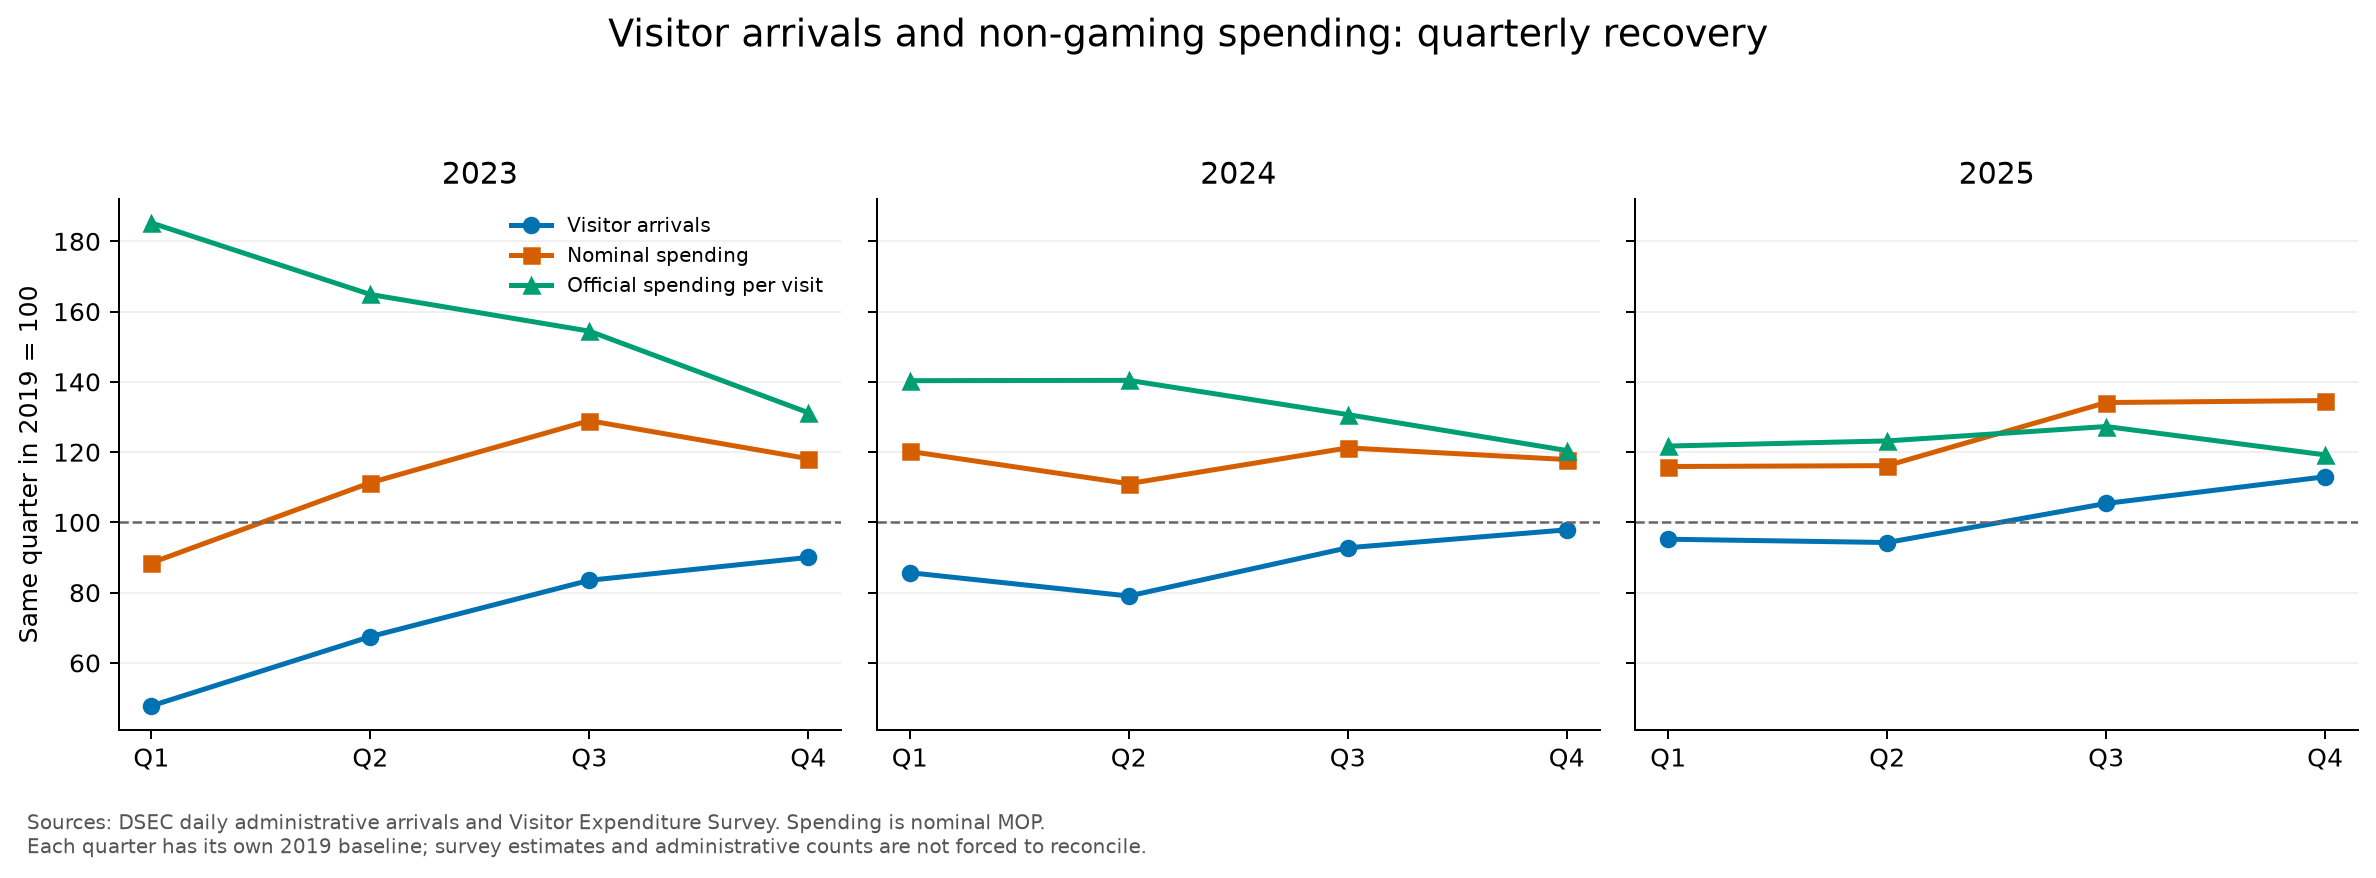

In [6]:
spending_fig, spending_axes = plt.subplots(1, 3, figsize=(13.3, 4.8), sharey=True)
spending_line_specs = [
    ("total_arrivals_index_2019q100", "Visitor arrivals", "#0072B2", "o"),
    ("total_nominal_spending_index_2019q100", "Nominal spending", "#D55E00", "s"),
    ("total_official_per_capita_spending_index_2019q100", "Official spending per visit", "#009E73", "^")]
for spending_ax, spending_year in zip(spending_axes, [2023, 2024, 2025]):
    spending_subset = spending_joined[spending_joined.year.eq(spending_year)]
    for spending_column, spending_label, spending_color, spending_marker in spending_line_specs:
        spending_ax.plot(spending_subset.quarter, spending_subset[spending_column],
                         color=spending_color, marker=spending_marker, label=spending_label, lw=2)
    spending_ax.axhline(100, color="#666666", ls="--", lw=1)
    spending_ax.set(title=str(spending_year), xticks=[1, 2, 3, 4], xticklabels=["Q1", "Q2", "Q3", "Q4"])
    spending_ax.grid(axis="y", alpha=.18)
spending_axes[0].set_ylabel("Same quarter in 2019 = 100")
spending_axes[0].legend(loc="upper right", fontsize=8, frameon=False)
spending_fig.suptitle("Visitor arrivals and non-gaming spending: quarterly recovery", fontsize=15, y=.99)
spending_save_figure(spending_fig, "11_quarterly_spending_recovery.png",
    "Sources: DSEC daily administrative arrivals and Visitor Expenditure Survey. Spending is nominal MOP.\n"
    "Each quarter has its own 2019 baseline; survey estimates and administrative counts are not forced to reconcile.")

### Reading Figure 11

The figure is embedded above and saved as [11_quarterly_spending_recovery.png](figures/11_quarterly_spending_recovery.png).

Start with 2025. In Q1 and Q2, the blue line is below 100 while the orange and green lines are above it. Arrivals below the pre-pandemic same-quarter level can coexist with nominal expenditure and spending per visit above it. All three indices exceed 100 in Q3 and Q4, but do not coincide: Q4 is approximately 113.0, 134.7 and 119.2, respectively.

Across the three panels, 2023's arrival and per-visit indices are also far apart. Arrival counts alone do not summarize expenditure performance. These lines describe quarterly aggregates; they are not forecasts or regression fits and provide no error bands or significance claims.

This directly supports RQ4's comparison. It does not identify a policy cause or represent recovery after removing price changes.


## Code cell 7 | Figure 12 compares spending per visit by type

### Purpose

Compare the two published visitor-type means so the overall mean does not hide differences between overnight and same-day visits. These are category means, not individual expenditure distributions.

### Method

The panels show overnight and same-day spending. Each has four annual lines for 2019, 2023, 2024 and 2025, using consistent colours and markers to distinguish years. Both horizontal axes run from Q1 to Q4.

`sharey=True` and `ylim=(0, 5100)` impose a common MOP scale. Vertical distances across panels then represent comparable amounts; independent automatic scales would make visual comparisons unreliable.

The vertical axis uses `*_per_capita_spending_mop`: **official non-gaming spending per visit in nominal MOP**, not the derived measure. Overnight visitors are a broader group than hotel guests, so the panels must not be relabelled as hotel versus non-hotel visitors.

### Course links

- Lecture04, **Introduction to Exploratory Data Analysis**, pp. 85-86: conditional displays.
- Lecture05, **Introduction to Data Visualization Plots**, pp. 5-9 and 88-89: line plots and clear, consistent encoding.
- Lecture06, **Introduction to Matplotlib**, pp. 68-84: multiple panels and shared axes. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451).
- Interpretation of group differences: Tutorial05-02, pp. 43-49. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848).


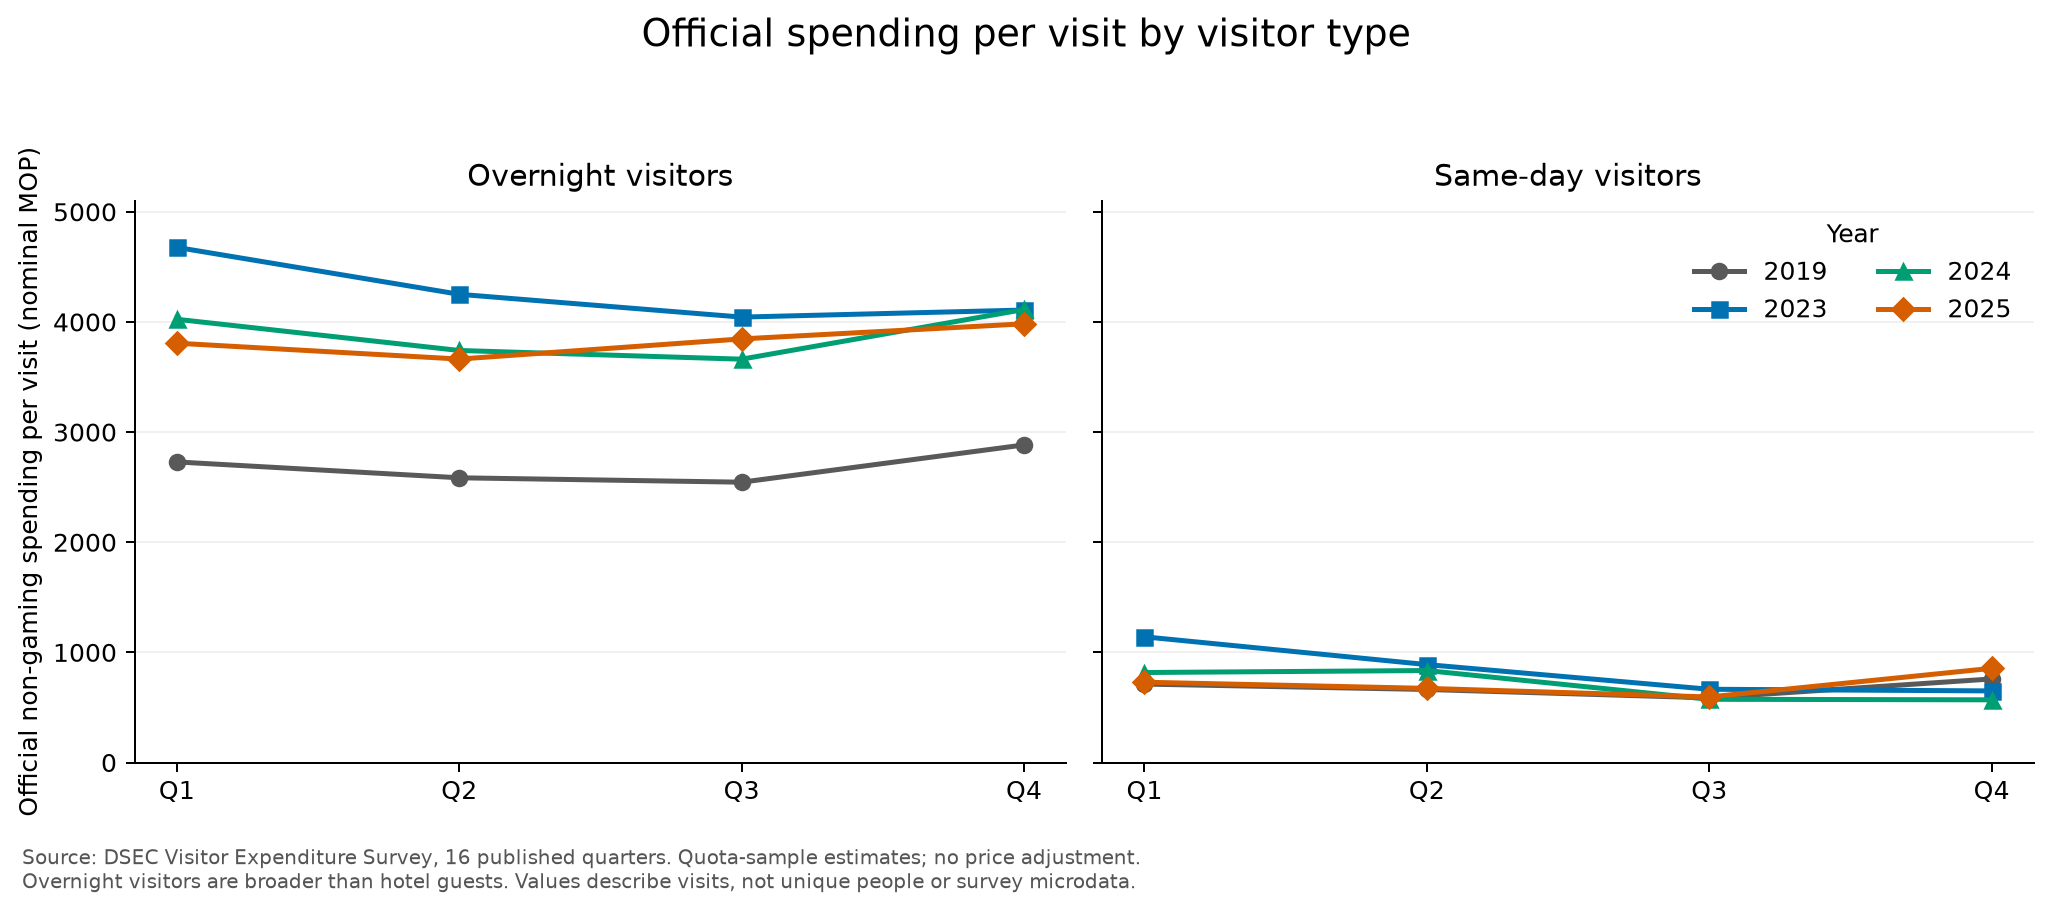

In [7]:
spending_fig, spending_axes = plt.subplots(1, 2, figsize=(11.5, 5), sharey=True)
for spending_ax, spending_kind, spending_title in zip(spending_axes, ["overnight", "same_day"], ["Overnight visitors", "Same-day visitors"]):
    for spending_year in SPENDING_YEARS:
        spending_subset = spending_joined[spending_joined.year.eq(spending_year)]
        spending_ax.plot(spending_subset.quarter, spending_subset[f"{spending_kind}_per_capita_spending_mop"],
                         color=SPENDING_YEAR_COLORS[spending_year], marker=SPENDING_YEAR_MARKERS[spending_year],
                         label=str(spending_year), lw=2)
    spending_ax.set(title=spending_title, xticks=[1, 2, 3, 4], xticklabels=["Q1", "Q2", "Q3", "Q4"], ylim=(0, 5100))
    spending_ax.grid(axis="y", alpha=.18)
spending_axes[0].set_ylabel("Official non-gaming spending per visit (nominal MOP)")
spending_axes[1].legend(title="Year", frameon=False, ncol=2, loc="upper right")
spending_fig.suptitle("Official spending per visit by visitor type", fontsize=15, y=.99)
spending_save_figure(spending_fig, "12_spending_per_visit_by_type.png",
    "Source: DSEC Visitor Expenditure Survey, 16 published quarters. Quota-sample estimates; no price adjustment.\n"
    "Overnight visitors are broader than hotel guests. Values describe visits, not unique people or survey microdata.")

### Reading Figure 12

The saved figure is [12_spending_per_visit_by_type.png](figures/12_spending_per_visit_by_type.png). The 2025 official estimates are below, in MOP:

| Quarter | Overall per visit | Overnight per visit | Same-day per visit | Overnight / same-day ratio |
|---|---:|---:|---:|---:|
| Q1 | 1,989 | 3,807 | 729 | 5.22 |
| Q2 | 1,950 | 3,663 | 673 | 5.44 |
| Q3 | 1,950 | 3,846 | 595 | 6.46 |
| Q4 | 2,104 | 3,983 | 855 | 4.66 |

First compare the level of expenditure across panels, then compare years within each panel. **Official spending per overnight visit exceeds same-day spending in all 16 observed quarters.** Ratios in 2025 range from about 4.66 to 6.46. These compare quarter-level category means; they do not predict how much the same person would spend if they changed to an overnight visit.

The figure contains no individual medians, variances, box plots or quantiles. It cannot show that every overnight visitor spends more or that individual expenditure is more evenly distributed. The published survey estimates use quota sampling and extrapolation; respondent microdata are unavailable here.

This supports RQ4's visitor-type comparison and the composition link to RQ1. It does not estimate a causal effect of length of stay.


## Code cell 8 | Figure 13 separates arrival and expenditure shares

### Purpose

Show the overnight share of visits alongside its share of non-gaming expenditure. Arrival composition and expenditure composition are different quantities.

### Method

The left panel plots `overnight_arrivals_share_pct`; the right plots `overnight_spending_share_pct`. Each has four annual lines by quarter and a shared 0-100% vertical scale.

The left denominator is administrative total arrivals; the right is the survey's published expenditure total. Their common percentage scale supports visual comparison, but their sources and denominators remain different.

Subtracting the corresponding 2019 share gives a difference in percentage points. The code does not renormalize expenditure components or assign rounding residuals to either category.

### Course links

- Lecture04, **Introduction to Exploratory Data Analysis**, pp. 57-67: category proportions; Lecture05, **Introduction to Data Visualization Plots**, pp. 42-57: composition and denominators.
- Tutorial05-02, **Exploring Relationships between Two Variables**, pp. 3-10: proportions, differences and ratios. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848).
- Lecture06, pp. 68-84: shared coordinates for comparisons across panels. [Matplotlib slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451).


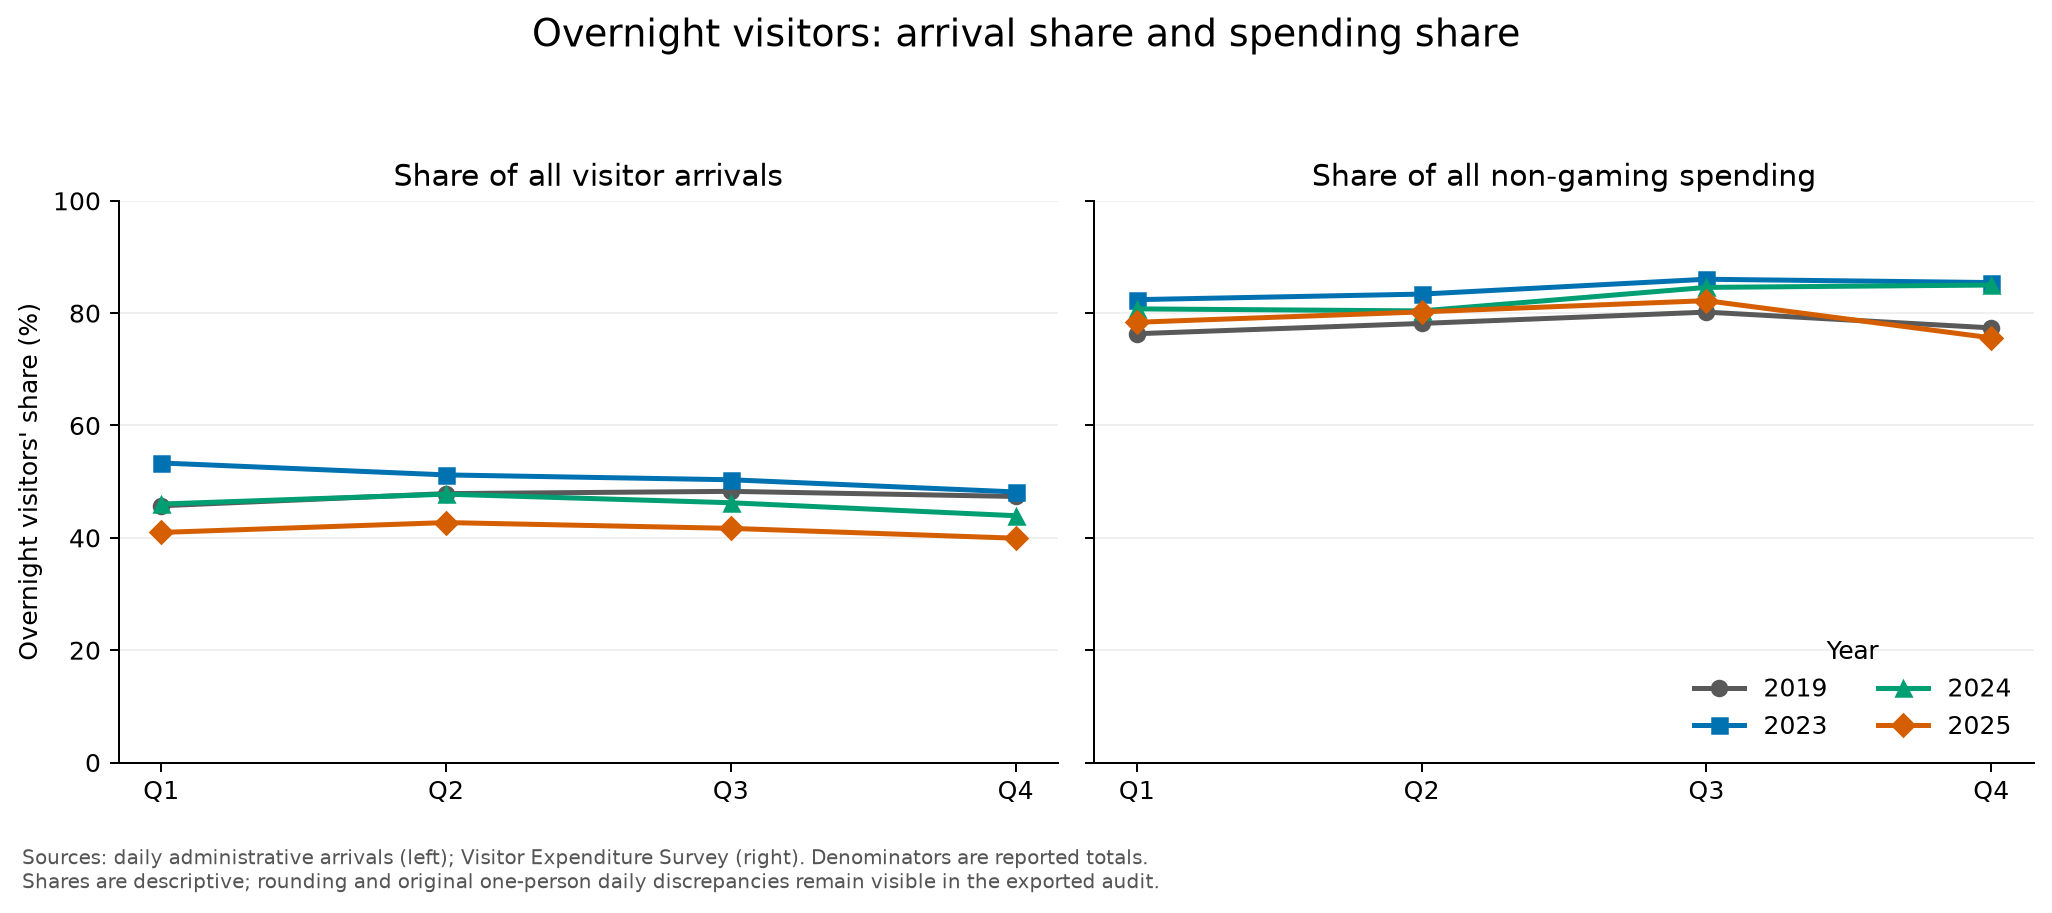

In [8]:
spending_fig, spending_axes = plt.subplots(1, 2, figsize=(11.5, 5), sharey=True)
for spending_ax, spending_column, spending_title in zip(spending_axes,
        ["overnight_arrivals_share_pct", "overnight_spending_share_pct"],
        ["Share of all visitor arrivals", "Share of all non-gaming spending"]):
    for spending_year in SPENDING_YEARS:
        spending_subset = spending_joined[spending_joined.year.eq(spending_year)]
        spending_ax.plot(spending_subset.quarter, spending_subset[spending_column],
                         color=SPENDING_YEAR_COLORS[spending_year], marker=SPENDING_YEAR_MARKERS[spending_year],
                         label=str(spending_year), lw=2)
    spending_ax.set(title=spending_title, xticks=[1, 2, 3, 4], xticklabels=["Q1", "Q2", "Q3", "Q4"], ylim=(0, 100))
    spending_ax.grid(axis="y", alpha=.18)
spending_axes[0].set_ylabel("Overnight visitors' share (%)")
spending_axes[1].legend(title="Year", frameon=False, ncol=2, loc="lower right")
spending_fig.suptitle("Overnight visitors: arrival share and spending share", fontsize=15, y=.99)
spending_save_figure(spending_fig, "13_overnight_arrival_spending_shares.png",
    "Sources: daily administrative arrivals (left); Visitor Expenditure Survey (right). Denominators are reported totals.\n"
    "Shares are descriptive; rounding and original one-person daily discrepancies remain visible in the exported audit.")

### Reading Figure 13

The saved figure is [13_overnight_arrival_spending_shares.png](figures/13_overnight_arrival_spending_shares.png).

| 2025 quarter | Overnight arrival share | Overnight expenditure share | Arrival-share change from matching 2019 quarter (pp) | Expenditure-share change from matching 2019 quarter (pp) |
|---|---:|---:|---:|---:|
| Q1 | 41.0% | 78.4% | -4.75 | +2.04 |
| Q2 | 42.7% | 80.2% | -5.15 | +2.05 |
| Q3 | 41.7% | 82.2% | -6.59 | +2.04 |
| Q4 | 39.9% | 75.6% | -7.43 | -1.78 |

In 2025, overnight visitors accounted for roughly two-fifths of arrivals but about three-quarters to more than four-fifths of non-gaming expenditure. This is consistent with their higher spending per visit in Figure 12. A smaller arrival share does not imply a smaller expenditure share.

The overnight **arrival share was lower in all four quarters** than in the matching 2019 quarter. Its expenditure share was higher in Q1-Q3 and lower only in Q4. Therefore, a falling overnight arrival share does not mean its expenditure share fell in every quarter. For example, the Q4 arrival share changed from 47.3632% to 39.9284%, a difference of -7.4348 **percentage points**, not -7.4348%.

This connects RQ1's overnight composition to RQ4's expenditure structure. It does not measure profits, welfare or policy effects. Full precision is in the [visitor-type comparison table](results/spending_visitor_type_comparison.csv).


## Code cell 9 | Save precise findings, input hashes and limits

### Purpose

Save the values behind the figures together with quality checks and measurement definitions. Each main finding can then be traced to a result table and official source, rather than relying on a picture alone.

### Method

- For each visitor category, find the largest absolute percentage difference among the 48 per-visit checks and separately record the maximum absolute MOP difference. The maxima need not come from the same row.
- `spending_summary` stores years and observation units, coverage of 1,461 days, raw quality flags, 2025 indices and type comparisons, annual comparisons, definitions and limitations.
- Compute SHA-256 hashes for the four key input CSVs. Hashes detect changed input files; they do not establish that the source is free of measurement error.
- Write `spending_summary.json` and `spending_findings.txt`, including paths to tables and figures. `executed_at_utc` is the program execution time, not the data publication date. A source's last-modified time is not necessarily its original publication date either.
- Generate findings from the computed tables while stating that expenditure is nominal and non-gaming and the analysis is descriptive, with no factor decomposition.

### Course links

- Tutorial02-02, **50 Years of Data Science**, pp. 69-75: sharing verifiable computational results.
- Tutorial05-01, **ThinkStats2 Distributions**, pp. 31 and 36: communicating to readers and reporting limitations; Tutorial04-01, pp. 36-42: checking against sources.
- Tutorial10-02, **Estimation**, pp. 17-31: sampling error versus bias and measurement error. [Slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266953).
- The [course AI policy](https://ummoodle.um.edu.mo/mod/page/view.php?id=1149869) requires disclosure and citation of AI use. Distinguish computed findings from explanatory writing.


In [9]:
spending_2025 = spending_joined[spending_joined.year.eq(2025)]
spending_consistency_summary = []
for spending_kind in SPENDING_KINDS:
    spending_group = spending_consistency[spending_consistency.visitor_type.eq(spending_kind)]
    spending_largest = spending_group.loc[spending_group.derived_minus_official_pct.abs().idxmax()]
    spending_consistency_summary.append({
        "visitor_type": spending_kind,
        "max_absolute_difference_mop": float(spending_group.derived_minus_official_mop.abs().max()),
        "max_absolute_difference_pct": float(spending_group.derived_minus_official_pct.abs().max()),
        "period_of_max_absolute_pct_difference": spending_largest.period,
        "signed_difference_mop_at_max_pct": float(spending_largest.derived_minus_official_mop),
    })
spending_summary = {
    "executed_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version.split()[0],
    "coverage": {"years": SPENDING_YEARS, "quarter_rows": len(spending_joined),
        "daily_rows_in_selected_years": len(spending_daily_selected),
        "all_selected_quarters_complete": True,
        "same_day_raw_missing_days": int(spending_daily_selected.raw_same_day_missing.sum()),
        "raw_type_additivity_flag_days": int(spending_daily_selected.raw_type_additivity_flag.sum()),
        "quarterly_arrival_type_residuals": spending_joined[["period", "analysis_type_sum_minus_total_arrivals"]].to_dict("records")},
    "measurement": {"spending_currency": "MOP", "spending_price_basis": "nominal_current_prices",
        "spending_excludes": "gaming", "spending_source": "DSEC quota-sample Visitor Expenditure Survey",
        "arrivals_source": "DSEC daily administrative visitor arrivals",
        "observation_unit": "city-quarter", "recovery_index_baseline": "same calendar quarter in 2019 = 100",
        "inference": "descriptive only; no causal attribution, confidence intervals, price deflation or decomposition"},
    "recovery_2025": spending_2025[["period"] + spending_recovery_columns].to_dict("records"),
    "type_comparison_2025": spending_2025[spending_structure_columns].to_dict("records"),
    "annual_crosscheck": spending_annual.to_dict("records"),
    "annual_comparisons_2025_vs_2019_and_2024": spending_annual_comparisons.to_dict("records"),
    "per_capita_consistency": spending_consistency_summary,
    "quarterly_spending_type_residuals_million_mop": spending_joined[["period", "component_sum_minus_reported_total_million_mop"]].to_dict("records"),
    "inputs": [{"file": str(path.relative_to(SPENDING_ROOT)),
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest()} for path in (
        SPENDING_DATA / SPENDING_INPUT_NAME,
        SPENDING_DATA / "macao_daily_total_overnight_sameday_2017_2025.csv",
        SPENDING_DATA / "spending_annual_controls.csv",
        SPENDING_DATA / "spending_annual_per_capita_controls.csv")],
    "csv_outputs": [str(path.relative_to(SPENDING_ROOT)) for path in sorted(SPENDING_RESULTS.glob("spending_*.csv"))],
    "figures": ["figures/11_quarterly_spending_recovery.png", "figures/12_spending_per_visit_by_type.png",
                "figures/13_overnight_arrival_spending_shares.png"],
}
(SPENDING_ROOT / "spending_summary.json").write_text(json.dumps(spending_summary, ensure_ascii=False, indent=2), encoding="utf-8")
spending_findings = [
    "Quarterly visitor-spending experiment — executed results",
    "16 individual quarters: Q1–Q4 in 2019, 2023, 2024 and 2025. All selected daily quarters are complete.",
    "All spending is nominal MOP, excluding gaming. Recovery indices use the corresponding 2019 quarter = 100.",
    "", "2025 matched-quarter recovery (arrivals / nominal spending / official spending per visit):"]
for spending_row in spending_2025.to_dict("records"):
    spending_findings.append(
        f"{spending_row['period']}: {spending_row['total_arrivals_index_2019q100']:.1f} / "
        f"{spending_row['total_nominal_spending_index_2019q100']:.1f} / "
        f"{spending_row['total_official_per_capita_spending_index_2019q100']:.1f}; "
        f"overnight arrival share {spending_row['overnight_arrivals_share_pct']:.1f}%, "
        f"spending share {spending_row['overnight_spending_share_pct']:.1f}%; "
        f"overnight/same-day official per-visit spending ratio {spending_row['overnight_to_same_day_official_per_capita_ratio']:.2f}.")
spending_findings += ["", "Annual total-visitor comparisons (nominal; official annual per-capita values):"]
for spending_item in spending_annual_comparisons[spending_annual_comparisons.visitor_type.eq("total")].to_dict("records"):
    spending_findings.append(
        f"2025 vs {spending_item['base_year']}: arrivals "
        f"{spending_item['daily_summed_annual_arrivals_change_pct']:+.4f}%; "
        f"quarter-summed spending {spending_item['quarter_summed_spending_million_mop_change_pct']:+.4f}%; "
        f"published annual spending {spending_item['published_annual_spending_million_mop_change_pct']:+.4f}%; "
        f"official annual spending per visit {spending_item['published_annual_per_capita_mop_change_pct']:+.4f}%.")
spending_findings += [
    "2019 annual spending: quarter sum 64,078 vs published annual control 64,077 million MOP; "
    "2024: 75,357 vs 75,358; 2025: 80,122 vs 80,122. Annual comparisons retain both bases.",
    "Annual per-capita estimates are taken from annual source tables, never obtained by averaging quarterly per-capita values.",
    "", "Official-versus-derived per-visit audit:"]
for spending_item in spending_consistency_summary:
    spending_findings.append(
        f"{spending_item['visitor_type']}: largest absolute discrepancy "
        f"{spending_item['max_absolute_difference_pct']:.4f}% "
        f"({spending_item['period_of_max_absolute_pct_difference']}); "
        f"maximum absolute MOP discrepancy across quarters {spending_item['max_absolute_difference_mop']:.4f}.")
spending_findings += [
    "", "Interpretation and limits:",
    "Compare each 2025 quarter with its matching 2019 quarter: a return of arrival counts need not imply an identical spending index. These are separate descriptive measurements, not a factor decomposition.",
    "Overnight visitors account for a much larger fraction of non-gaming spending than of arrivals. Official spending per overnight visit exceeds same-day spending in every observed quarter.",
    "The spending survey uses quota sampling and extrapolation; arrival counts are administrative. They are separate data sources, not statistically independent variables or visitor-level linked records.",
    "Published total and type spending have rounding differences of up to 1 million MOP. Existing daily type anomalies are retained and counted. No arithmetic residual is assigned to a visitor type.",
    "Derived spending per visit is total reported spending divided by summed daily arrivals; the exported differences document rounding/revision/source compatibility, without assuming exact equality.",
    "No claim is made about real purchasing power, individual spending distributions, tourism GDP, gaming revenue, profit or policy effects. No TPI, Shapley, confidence intervals or respondent-level inference is used.",
    "Source definitions and the historical wording change for overnight visitors are documented in data/README.txt. Original per-capita precision is preserved; round to whole MOP in presentations.",
]
(SPENDING_ROOT / "spending_findings.txt").write_text("\n".join(spending_findings) + "\n", encoding="utf-8")
print("\n".join(spending_findings))

Quarterly visitor-spending experiment — executed results
16 individual quarters: Q1–Q4 in 2019, 2023, 2024 and 2025. All selected daily quarters are complete.
All spending is nominal MOP, excluding gaming. Recovery indices use the corresponding 2019 quarter = 100.

2025 matched-quarter recovery (arrivals / nominal spending / official spending per visit):
2025Q1: 95.2 / 115.9 / 121.7; overnight arrival share 41.0%, spending share 78.4%; overnight/same-day official per-visit spending ratio 5.22.
2025Q2: 94.3 / 116.1 / 123.2; overnight arrival share 42.7%, spending share 80.2%; overnight/same-day official per-visit spending ratio 5.44.
2025Q3: 105.4 / 134.1 / 127.3; overnight arrival share 41.7%, spending share 82.2%; overnight/same-day official per-visit spending ratio 6.46.
2025Q4: 113.0 / 134.7 / 119.2; overnight arrival share 39.9%, spending share 75.6%; overnight/same-day official per-visit spending ratio 4.66.

Annual total-visitor comparisons (nominal; official annual per-capita va

### Results and contribution to the proposal

The output reports same-quarter recovery, both annual comparisons, the largest consistency differences and interpretation limits. Full results are in [spending_summary.json](spending_summary.json); the concise narrative is in [spending_findings.txt](spending_findings.txt). Both are generated by this notebook.

The main finding is: **2025 arrivals, nominal non-gaming expenditure and official spending per visit recovered by different amounts; per-visit changes have opposite signs against 2019 and 2024; and overnight visitors account for a smaller share of arrivals than of expenditure.** This answers RQ4 and connects to RQ1, without making an untested expenditure forecast.

Survey questionnaire counts are not this experiment's sample size. The 2019Q4 source describes roughly 16,000 valid questionnaires in the quarter and 87,000 in the year. We have the published aggregates, not those questionnaires, and cannot use those counts to construct visitor-level confidence intervals for our 16-quarter analysis.


## Measurement details that matter throughout the analysis

See [data/README.txt](data/README.txt) for fields and definitions. Expenditure CSVs retain official publication links; annual controls also retain source-table locations. These details govern interpretation of the fixed input version.

1. **Individual quarters and cumulative periods are distinct.** The 2019Q1-Q3 sources use legacy XLS; Q4 uses XLSX. Quarterly totals were taken from the corresponding PDFs and per-visit estimates from the spreadsheets. Individual Q2, Q3 and Q4 rows were distinguished from Q1-Q2, Q1-Q3 and Q1-Q4 cumulative rows. A Q4 historical table is not a substitute for the 16 quarterly releases.
2. **Year-column positions changed.** Current-year values are in B/E/H for 2023-2024 and C/F/I for 2025. Extraction checked the year headers rather than assuming the leftmost numeric column was current.
3. **Stored and displayed precision differ.** The 2019Q4 workbook stores decimal per-visit values while PDFs often show integers. The 2019 annual official value is retained as 1626.0734524407242 MOP. Extra decimal places are not greater statistical certainty; presentations may use whole MOP.
4. **Sources and observation units differ.** Administrative arrivals and quota-survey expenditure are joined by quarter. This does not produce individual expenditure distributions, deduplicated visitors or thousands of independent observations.
5. **The wording of overnight status changed.** The 2019 definition refers to spending at least one night in residential accommodation or a casino; 2023/2025 wording also includes visitors with hotel accommodation arrangements. Overnight visitors are broader than hotel guests. Disclose this difference without treating wording alone as proof of a methodological break. Methodology/glossary locations: 2019Q4 p. 8, 2023Q4 p. 6 and 2025Q4 p. 4.
6. **Gaming was excluded before 2025.** The newer label makes this explicit; it did not introduce the exclusion. Expenditure also excludes donations, asset purchases and goods for resale. It is not gaming revenue, tourism GDP, business profit or resident welfare.
7. **Differences were not forced to balance.** Reported totals, components, annual controls and daily quality flags remain separate. Converting million MOP to MOP neither removes rounding nor adds information.

## How this notebook supports the proposal

| Research question | Evidence in this notebook | Interpretation boundary |
|---|---|---|
| RQ1: How did total arrivals, overnight/same-day composition and source composition change between 2019 and 2025? | Quarterly visitor-type counts and shares; Figure 13 compares arrival and expenditure shares | Supports visitor-type composition. Source composition is in the daily notebook; these expenditure data have no source-region breakdown |
| RQ2: How did the typical level, spread and upper quantiles of daily arrivals change, and did changes vary by month and weekday? | No direct daily-distribution analysis here | Daily distributions and high-arrival comparisons are in the companion notebook; 16 expenditure quarters cannot reveal daily spending distributions |
| RQ3: How did calendar models selected using 2024 validation perform in 2025, and how did trend and Ridge affect errors? | No predictive model is fitted or evaluated here | The companion notebook's calendar-model scores cannot be presented as expenditure forecasts |
| RQ4: Did arrivals, nominal non-gaming expenditure and official spending per visit recover together under same-quarter and annual comparisons? | Figure 11 recovery indices, Figure 12 category means, Figure 13 shares, annual comparisons and consistency checks | Describes the 16 quarters in four selected years; supports uneven, baseline-dependent recovery, not factor or causal attribution |

Always state the **baseline, unit, nominal-price basis and visitor category**. A supported summary is: compared with 2019, 2025 annual arrivals rose about 1.68%, official nominal non-gaming expenditure 25.04% and official spending per visit 23.00%; compared with 2024, the changes were +14.72%, +6.32% and -7.28%. Do not reduce this to an unqualified claim that expenditure failed to recover, or call the 23.00% change real purchasing-power growth.

The course sequence is **data wrangling and validation → descriptive statistics and proportions → stratification and weighted-mean interpretation → comparable multi-panel figures → traceable conclusions**. We did not run Shapley or index-factor decomposition, fixed-composition counterfactuals, TPI deflation, confidence intervals, significance tests or policy-effect estimation. A method's inclusion in the course does not establish that 16 aggregate quarters meet its sampling and dependence assumptions.

## Course and result references

- Data preparation: Tutorial04-01, **ThinkStats2 EDA**, pp. 30-42; [Pandas course material](https://ummoodle.um.edu.mo/mod/page/view.php?id=1153067).
- Observation units, weighted means and stratification: Lecture04, **Introduction to Exploratory Data Analysis**, pp. 11-18, 20-26, 57-67 and 85-86; [course catalogue](https://ummoodle.um.edu.mo/course/view.php?id=46674).
- Proportions and interpretation: Tutorial05-02, **Exploring Relationships between Two Variables**, pp. 3-10 and 43-49; [slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1218848).
- Chart choice: Lecture05, **Introduction to Data Visualization Plots**, pp. 5-9, 42-57 and 88-89. Implementation: Lecture06, **Introduction to Matplotlib**, pp. 8-45 and 68-84; [slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1231451).
- Sampling and uncertainty: Lecture10, **Data and Sampling Distributions**, pp. 3-17 and 26-56, [slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266908); Tutorial10-02, **Estimation**, pp. 17-31, [slides](https://ummoodle.um.edu.mo/mod/resource/view.php?id=1266953).
- Outputs: [joined quarterly data](results/spending_quarterly_joined.csv), [annual cross-check](results/spending_annual_crosscheck.csv), [annual comparisons](results/spending_annual_comparisons.csv) and [data definitions](data/README.txt).

**Maintenance:** The interpretation describes the saved results. If inputs, official revisions, definitions or code change, rerun the analysis and review all written numbers, definitions and figure interpretations. Explanatory text does not update automatically when code runs.
